# Final held-out test — kNN + E5 routing policy

**Reproducible, frozen-policy evaluation.** The candidate pool includes GPT-4, and GPT-4 can also serve as a fixed-model reference. This notebook does not retrain or tune models, does not search over λ, and does not use test labels until the policy configuration and validation-prediction reproduction checks pass.

**Inputs:** canonical prepared RouterBench splits, a completed calibration-first `full/` modeling run, and a λ selected during validation for **kNN + E5 (388 features) + expected score**.

**KPI definitions:** `kpis.md`. RouterBench's recorded scores may be fractional; the notebook does **not** automatically interpret fractional scores as binary correctness. Binary-only diagnostics are marked unavailable unless binary outcomes are supplied. The validation reference rule must be finalized *before* test inspection.

## 0. Freeze configuration and locate source artifacts

Find the chosen λ in the validation-stage policy-selection output for `model='knn'`, `embed='e5'`, `split='validation'`, `score_type='expected'`. Enter its **full precision** below. Verify the reference LLM was chosen from validation only. Set both confirmations to `True` only when those choices are frozen. All 11 LLMs, including GPT-4, remain eligible for routing.

The recorded outcomes in Step 1 are **not loaded** until these checks pass.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# ---- Fill in values chosen on VALIDATION, before evaluating test ----
FROZEN_LAMBDA = 3.3010409462330443                   # e.g., 17.123456789; MUST replace with actual kNN + E5 lambda
LAMBDA_CONFIRMED = True
FROZEN_REFERENCE_LLM = "gpt-4-1106-preview"           # Reference selected on validation, e.g. "gpt-4-1106-preview"
REFERENCE_CONFIRMED = True           # Reference selected per pre-agreed validation criterion
# NOTE: if validation labels are graded, selecting highest mean graded score is
# a proxy, not the binary-accuracy criterion specified in kpis.md.

PROJECT_ROOT_OVERRIDE = None          # Optional absolute project root
FULL_RUN_DIR_OVERRIDE = None          # Optional absolute path to model outputs/full
SCORE_TYPE = "expected"
FEATURE = "e5_388"
METHOD = "kNN"
RNG_SEED = 42
BOOTSTRAP_REPLICATES = 2000

cwd = Path.cwd().resolve()
project_candidates = [cwd, *cwd.parents]
if PROJECT_ROOT_OVERRIDE is not None:
    project_candidates = [Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()]
project_root = next((p for p in project_candidates if
    (p / "1_data_preparation/data/processed/char_tfidf_50k/preprocessing.joblib").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Cannot identify project root. Set PROJECT_ROOT_OVERRIDE.")
run_dir = (Path(FULL_RUN_DIR_OVERRIDE).expanduser().resolve() if FULL_RUN_DIR_OVERRIDE else
           project_root / "2_Router_Training/experiment_outputs/score_classification_5class/full")
required = ("experiment_manifest.json", "predictions_manifest.csv", "run_status.json")
for f in required:
    if not (run_dir / f).is_file():
        raise FileNotFoundError(f"Missing modeling artifact: {run_dir / f}")
manifest = json.loads((run_dir / "experiment_manifest.json").read_text())
status = json.loads((run_dir / "run_status.json").read_text())
assert status.get("mode") == "full" and status.get("status") == "completed", status
assert manifest.get("mode") == "full" and manifest.get("test_used") is False
assert manifest.get("evaluation_split") == "calibration"
assert manifest.get("validation_role") == "downstream routing-policy development"
model_names = list(manifest["model_names"])
assert len(model_names) == 11 and "gpt-4-1106-preview" in model_names
selected_score_k = int(manifest["selected_knn_score_k"][FEATURE])
selected_cost_k = int(manifest["selected_knn_cost_k"][FEATURE])
assert selected_score_k > 0 and selected_cost_k > 0
prediction_manifest = pd.read_csv(run_dir / "predictions_manifest.csv")
matching = prediction_manifest.loc[
    (prediction_manifest["method"] == METHOD) &
    (prediction_manifest["embedding"] == FEATURE) &
    (prediction_manifest["split"] == "validation")
]
assert len(matching) == 1, "Expected exactly one kNN/E5/validation bundle"
validation_prefix = str(matching.iloc[0]["prefix"])
for suffix in ("_expected_score.pkl", "_dollar_cost.pkl"):
    assert (run_dir / (validation_prefix + suffix)).is_file(), validation_prefix + suffix
assert int(matching.iloc[0]["score_k"]) == selected_score_k
assert int(matching.iloc[0]["cost_k"]) == selected_cost_k

print("Project root:", project_root)
print("Completed model run:", run_dir)
print("Validation bundle:", validation_prefix)
print("kNN neighbors — scores:", selected_score_k, "costs:", selected_cost_k)
print("Candidates:", len(model_names), "(including GPT-4)")
if not (LAMBDA_CONFIRMED and REFERENCE_CONFIRMED and
        FROZEN_LAMBDA is not None and np.isfinite(FROZEN_LAMBDA) and FROZEN_LAMBDA >= 0 and
        FROZEN_REFERENCE_LLM in model_names):
    raise RuntimeError("Freeze λ and the validation-chosen reference before accessing test data. Set both confirmation flags True.")
print("Frozen λ:", FROZEN_LAMBDA)
print("Frozen reference:", FROZEN_REFERENCE_LLM)

Project root: /Users/haotanhan/Documents/Career/DataScience/ErdosBootCamp/Project/fall-2026-right-for-less/fall-2026-right-for-less
Completed model run: /Users/haotanhan/Documents/Career/DataScience/ErdosBootCamp/Project/fall-2026-right-for-less/fall-2026-right-for-less/2_Router_Training/experiment_outputs/score_classification_5class/full
Validation bundle: pred_07_validation
kNN neighbors — scores: 80 costs: 10
Candidates: 11 (including GPT-4)
Frozen λ: 3.3010409462330443
Frozen reference: gpt-4-1106-preview


## 1. Rebuild the exact kNN predictions and check them against validation exports

The kNN index is **not** stored as a fitted estimator. Recreate it from the *canonical training E5 feature rows* using brute-force cosine distance. The score predictor uses training score-class frequencies among `score_k` neighbors; the cost predictor averages historical dollar costs among `cost_k` neighbors. These may be different neighbor counts.

Crucially, compare the recreated **validation** predictions against the saved validation bundle *before touching test labels*. If they disagree, stop and investigate feature, row order, package, or run mismatch.
**Reproducibility note:** Request the maximum `k` from the original neighbor-search grid, even when the selected score and cost values are smaller. Equal-distance ties can otherwise lead to different neighbor ordering.


In [2]:
prep = project_root / "1_data_preparation" / "data" / "processed"
table_dir = prep / "char_tfidf_50k"
e5_dir = prep / "multilingual_e5_small_chunk480"
support = np.asarray(manifest["score_support"], dtype=float)
assert support.shape == (5,)
train_questions = pd.read_pickle(table_dir / "train_questions.pkl")
train_scores = pd.read_pickle(table_dir / "train_scores.pkl")
train_costs = pd.read_pickle(table_dir / "train_costs.pkl")
validation_questions = pd.read_pickle(table_dir / "validation_questions.pkl")
for q, s, c in [(train_questions, train_scores, train_costs)]:
    assert q.index.is_unique and q.index.equals(s.index) and q.index.equals(c.index)
    assert s.columns.tolist() == c.columns.tolist() == model_names
X_train = np.load(e5_dir / "X_train_e5_full_features.npy", allow_pickle=False)
X_validation = np.load(e5_dir / "X_validation_e5_full_features.npy", allow_pickle=False)
assert X_train.shape == (len(train_questions), 388)
assert X_validation.shape == (len(validation_questions), 388)
# Training CV has already selected these values. Do not retune here.
training_values = train_scores.to_numpy(dtype=float)
training_classes = np.abs(training_values[..., None] - support).argmin(axis=2)
training_cost_values = train_costs.to_numpy(dtype=float)
assert np.all(np.isfinite(training_cost_values)) and np.all(training_cost_values > 0)
assert max(selected_score_k, selected_cost_k) <= len(train_questions)

nn = NearestNeighbors(metric="cosine", algorithm="brute", n_jobs=-1).fit(X_train)
def knn_predict(X, batch_size=128):
    """Mirror the modeling pipeline's uniform-neighbor score and dollar-cost estimators."""
    n = X.shape[0]
    p = np.empty((n, len(model_names), len(support)), dtype=float)
    c = np.empty((n, len(model_names)), dtype=float)
    # Match the modeling export exactly: it retrieves the largest k in the
    # FULL CV grid, then uses prefixes for selected score/cost k values.
    # Asking NearestNeighbors for only 80 instead of 100 can change tie order.
    max_k = max(int(k) for k in manifest["k_values"])
    assert max_k >= max(selected_score_k, selected_cost_k)
    llm_idx = np.arange(len(model_names))[None, :]
    for start in range(0, n, batch_size):
        stop = min(start + batch_size, n)
        neighbor_idx = nn.kneighbors(X[start:stop], n_neighbors=max_k, return_distance=False)
        z = training_classes[neighbor_idx[:, :selected_score_k]]
        # shape: batch x score_k x llm; count class frequencies per LLM
        p[start:stop] = (z[..., None] == np.arange(len(support))).mean(axis=1)
        c[start:stop] = training_cost_values[neighbor_idx[:, :selected_cost_k]].mean(axis=1)
    return p, c

p_validation, c_validation = knn_predict(X_validation)
validation_pred_score = pd.DataFrame(p_validation @ support,
                                      index=validation_questions.index, columns=model_names)
validation_pred_cost = pd.DataFrame(c_validation,
                                     index=validation_questions.index, columns=model_names)
export_score = pd.read_pickle(run_dir / f"{validation_prefix}_expected_score.pkl")
export_cost = pd.read_pickle(run_dir / f"{validation_prefix}_dollar_cost.pkl")
assert export_score.index.equals(validation_pred_score.index)
assert export_cost.index.equals(validation_pred_cost.index)
assert export_score.columns.tolist() == export_cost.columns.tolist() == model_names
score_diff = float(np.max(np.abs(export_score.to_numpy() - validation_pred_score.to_numpy())))
cost_diff = float(np.max(np.abs(export_cost.to_numpy() - validation_pred_cost.to_numpy())))
print("Max validation predicted-score discrepancy:", score_diff)
print("Max validation predicted-dollar-cost discrepancy:", cost_diff)
assert np.allclose(export_score.to_numpy(), validation_pred_score.to_numpy(), atol=1e-10, rtol=1e-8), "kNN score mismatch: stop before test"
assert np.allclose(export_cost.to_numpy(), validation_pred_cost.to_numpy(), atol=1e-10, rtol=1e-8), "kNN cost mismatch: stop before test"
print("Validation reproduction checks PASSED. Frozen configuration is ready for testing.")

Max validation predicted-score discrepancy: 0.0
Max validation predicted-dollar-cost discrepancy: 0.0
Validation reproduction checks PASSED. Frozen configuration is ready for testing.


## 2. Predict on test, then apply the frozen policy

No test outcome is used to predict costs, predict scores, select model indices, or choose λ. The 11-model pool **includes GPT-4**.

In [3]:
test_questions = pd.read_pickle(table_dir / "test_questions.pkl")
X_test = np.load(e5_dir / "X_test_e5_full_features.npy", allow_pickle=False)
assert X_test.shape == (len(test_questions), 388)
p_test, c_test = knn_predict(X_test)
predicted_scores = pd.DataFrame(p_test @ support, index=test_questions.index, columns=model_names)
predicted_costs = pd.DataFrame(c_test, index=test_questions.index, columns=model_names)
assert np.allclose(p_test.sum(axis=2), 1, atol=1e-10)
assert np.isfinite(predicted_scores.to_numpy()).all()
assert (predicted_costs.to_numpy() > 0).all()

objective = predicted_scores.to_numpy() - FROZEN_LAMBDA * predicted_costs.to_numpy()
choices = np.argmax(objective, axis=1)
selected_models = np.asarray(model_names)[choices]
print("Frozen policy selected (model counts):")
display(pd.Series(selected_models).value_counts().to_frame("test_questions"))

Frozen policy selected (model counts):


,test_questions
gpt-4-1106-preview,5093
zero-one-ai/Yi-34B-Chat,674
claude-v2,669
claude-v1,365
claude-instant-v1,249
gpt-3.5-turbo-1106,167
mistralai/mixtral-8x7b-chat,64
meta/code-llama-instruct-34b-chat,9
WizardLM/WizardLM-13B-V1.2,7
mistralai/mistral-7b-chat,2


## 3. Open test labels once and calculate the primary outcomes

`kpis.md` defines accuracy from **binary correctness**. RouterBench scores are on a graded scale and include values such as 0.25/0.5/0.75. The primary outputs here are therefore **mean recorded score** and **mean score difference**. They should not be called binary accuracy unless actual outcomes are binary. When scores are entirely 0/1, both interpretations coincide.

Reference is frozen on validation, never selected by looking at test accuracy.

In [4]:
true_scores = pd.read_pickle(table_dir / "test_scores.pkl")
true_costs = pd.read_pickle(table_dir / "test_costs.pkl")
assert test_questions.index.is_unique
assert test_questions.index.equals(true_scores.index) and test_questions.index.equals(true_costs.index)
assert true_scores.columns.tolist() == true_costs.columns.tolist() == model_names
S = true_scores.to_numpy(dtype=float)
C = true_costs.to_numpy(dtype=float)
assert np.all(np.isfinite(S)) and np.all((0 <= S) & (S <= 1))
assert np.all(np.isfinite(C)) and np.all(C > 0)
idx = np.arange(len(test_questions))
selected = pd.DataFrame({
    "selected_model": selected_models,
    "predicted_score": predicted_scores.to_numpy()[idx, choices],
    "actual_score": S[idx, choices],
    "predicted_cost_usd": predicted_costs.to_numpy()[idx, choices],
    "actual_cost_usd": C[idx, choices],
}, index=test_questions.index)
selected.index.name = "sample_id"
ref = FROZEN_REFERENCE_LLM
r_score = selected["actual_score"].to_numpy()
r_cost = selected["actual_cost_usd"].to_numpy()
b_score = true_scores[ref].to_numpy(dtype=float)
b_cost = true_costs[ref].to_numpy(dtype=float)
router_mean_score = float(r_score.mean())
ref_mean_score = float(b_score.mean())
router_mean_cost = float(r_cost.mean())
ref_mean_cost = float(b_cost.mean())
score_delta = router_mean_score - ref_mean_score
savings = 1 - router_mean_cost / ref_mean_cost
strict_binary = bool(np.all(np.isin(S, [0., 1.])))
print("Recorded test outcomes strictly binary?", strict_binary)
print(f"Routed mean recorded score: {router_mean_score:.6f}")
print(f"Reference mean recorded score: {ref_mean_score:.6f}")
print(f"Routed score difference: {score_delta:+.6f}")
print(f"Mean routed dollar cost: ${router_mean_cost:.8f}")
print(f"Mean reference dollar cost: ${ref_mean_cost:.8f}")
print(f"Relative cost savings: {savings:.2%}")
if not strict_binary:
    print("Binary accuracy, Brier and binary log loss are NOT reported from graded scores.")

Recorded test outcomes strictly binary? False
Routed mean recorded score: 0.777384
Reference mean recorded score: 0.779795
Routed score difference: -0.002411
Mean routed dollar cost: $0.00226914
Mean reference dollar cost: $0.00328008
Relative cost savings: 30.82%
Binary accuracy, Brier and binary log loss are NOT reported from graded scores.


## 4. KPI scorecard, model diagnostics and uncertainty

- **Primary:** mean score (binary accuracy *only if* labels are 0/1), difference versus frozen reference, mean response cost, relative savings.
- **Costs (all LLMs and routed choices):** MSE, MAE and Gamma deviance, as defined in `kpis.md`. Dollar costs must be positive.
- **Binary diagnostics:** Brier/MSE and binary log loss only when actual score labels across all evaluated models are strictly 0/1. kNN expected five-bin score is a *graded expected score*, **not automatically a calibrated binary correctness probability**; if binary labels happen to be available, the notebook reports it as a proxy with this limitation explicitly named.
- **Precision/recall:** unspecified in `kpis.md` and not applicable to regression outputs without a positive-class/threshold definition; omitted.
- **Latency:** historical cost tables don't contain all four latency components; marked unavailable.
- **Uncertainty:** paired bootstrap intervals for mean score difference and percentage savings. Test-only diagnostics must not be used to retune λ.

In [5]:
P = predicted_scores.to_numpy(dtype=float)
PC = predicted_costs.to_numpy(dtype=float)
EPS = 1e-12

def cost_metric_rows(y, pred, label):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)
    assert y.shape == pred.shape and np.all(y > 0) and np.all(pred > 0)
    gamma_deviance = y / pred - np.log(y / pred) - 1
    return {
        "group": label,
        "cost_mse_usd2": float(np.mean((pred - y)**2)),
        "cost_mae_usd": float(np.mean(np.abs(pred - y))),
        "cost_gamma_loss": float(np.mean(gamma_deviance)),
        "cost_wape": float(np.abs(pred - y).sum() / y.sum()),
    }

cost_diagnostics = pd.DataFrame([
    cost_metric_rows(C[:,j], PC[:,j], model_names[j]) for j in range(len(model_names))
] + [cost_metric_rows(r_cost, selected["predicted_cost_usd"], "ROUTED_SELECTION")])
# Equal-weight mean across models for each per-model diagnostic
mean_llm_diagnostics = cost_diagnostics.iloc[:len(model_names)].drop(columns="group").mean()
print("Cost prediction diagnostics by model, including the selected router:")
display(cost_diagnostics)
print("Equal-weight average across candidate LLMs:")
display(mean_llm_diagnostics.to_frame("mean_across_llms"))

rng = np.random.default_rng(RNG_SEED)
boot_delta, boot_savings = [], []
for _ in range(BOOTSTRAP_REPLICATES):
    ii = rng.integers(0, len(r_score), size=len(r_score))
    boot_delta.append(float((r_score[ii] - b_score[ii]).mean()))
    boot_savings.append(float(1 - r_cost[ii].mean() / b_cost[ii].mean()))
delta_ci = np.quantile(boot_delta, [.025, .975])
savings_ci = np.quantile(boot_savings, [.025, .975])

score_proxy_brier_per_llm = None
binary_log_loss_per_llm = None
if strict_binary:
    score_proxy_brier_per_llm = ((P - S) ** 2).mean(axis=0)
    clipped = np.clip(P, EPS, 1-EPS)
    binary_log_loss_per_llm = -(S*np.log(clipped) + (1-S)*np.log1p(-clipped)).mean(axis=0)
    print("Binary metrics computed using expected graded-score predictions as probability proxies;")
    print("these were NOT trained as binary probability estimators.")
else:
    print("Binary Brier and binary log loss unavailable (graded original scores).")

scorecard = pd.DataFrame([{
    "method": METHOD, "embedding": FEATURE, "score_type": SCORE_TYPE,
    "frozen_lambda": float(FROZEN_LAMBDA), "reference_llm": ref,
    "test_questions": len(test_questions), "candidate_llms": len(model_names),
    "score_neighbor_k": selected_score_k, "cost_neighbor_k": selected_cost_k,
    "score_label_type": "strict_binary" if strict_binary else "graded_0_to_1",
    "routed_mean_recorded_score": router_mean_score,
    "reference_mean_recorded_score": ref_mean_score,
    "score_difference_vs_reference": score_delta,
    "score_difference_ci95_lower": float(delta_ci[0]),
    "score_difference_ci95_upper": float(delta_ci[1]),
    "routed_mean_cost_usd": router_mean_cost,
    "reference_mean_cost_usd": ref_mean_cost,
    "relative_cost_savings": savings,
    "savings_ci95_lower": float(savings_ci[0]),
    "savings_ci95_upper": float(savings_ci[1]),
    "routed_accuracy_binary": router_mean_score if strict_binary else np.nan,
    "accuracy_change_binary": score_delta if strict_binary else np.nan,
    "candidate_binary_brier_mean_proxy": float(np.mean(score_proxy_brier_per_llm)) if strict_binary else np.nan,
    "candidate_binary_logloss_mean_proxy": float(np.mean(binary_log_loss_per_llm)) if strict_binary else np.nan,
    "candidate_cost_mse_mean_usd2": mean_llm_diagnostics["cost_mse_usd2"],
    "candidate_cost_mae_mean_usd": mean_llm_diagnostics["cost_mae_usd"],
    "candidate_cost_gamma_loss_mean": mean_llm_diagnostics["cost_gamma_loss"],
    "routed_cost_mse_usd2": cost_diagnostics.iloc[-1]["cost_mse_usd2"],
    "routed_cost_mae_usd": cost_diagnostics.iloc[-1]["cost_mae_usd"],
    "routed_cost_gamma_loss": cost_diagnostics.iloc[-1]["cost_gamma_loss"],
    "precision_recall": "undefined_without_threshold_or_positive_class",
    "end_to_end_latency": "unavailable_no_latency_records",
    "gpt4_selection_fraction": float((selected_models == "gpt-4-1106-preview").mean()),
}])
display(scorecard.T.rename(columns={0:"Held-out test result"}))

if strict_binary:
    binary_diagnostics = pd.DataFrame({
        "llm": model_names,
        "brier_expected_score_proxy": score_proxy_brier_per_llm,
        "binary_logloss_expected_score_proxy": binary_log_loss_per_llm
    })
    display(binary_diagnostics)
else:
    binary_diagnostics = pd.DataFrame(columns=["llm", "brier_expected_score_proxy", "binary_logloss_expected_score_proxy"])

Cost prediction diagnostics by model, including the selected router:


,group,cost_mse_usd2,cost_mae_usd,cost_gamma_loss,cost_wape
0,WizardLM/WizardLM-13B-V1.2,1.981451e-10,0.000006,0.006844,0.083457
1,claude-instant-v1,3.843802e-09,0.000026,0.009136,0.109667
2,claude-v1,4.405837e-07,0.000220,0.009624,0.102748
3,claude-v2,3.090622e-07,0.000237,0.006402,0.098055
4,gpt-3.5-turbo-1106,3.108848e-09,0.000024,0.007626,0.100789
5,gpt-4-1106-preview,1.376321e-06,0.000443,0.012259,0.135034
6,meta/code-llama-instruct-34b-chat,8.980409e-10,0.000014,0.006358,0.079947
7,meta/llama-2-70b-chat,2.040565e-09,0.000016,0.006140,0.078155
8,mistralai/mistral-7b-chat,7.602825e-10,0.000006,0.019743,0.127456
9,mistralai/mixtral-8x7b-chat,5.860035e-10,0.000011,0.006600,0.083755


Equal-weight average across candidate LLMs:


,mean_across_llms
cost_mse_usd2,1.944805e-07
cost_mae_usd,9.299099e-05
cost_gamma_loss,9.135766e-03
cost_wape,1.004632e-01


Binary Brier and binary log loss unavailable (graded original scores).


,Held-out test result
method,kNN
embedding,e5_388
score_type,expected
frozen_lambda,3.301041
reference_llm,gpt-4-1106-preview
test_questions,7300
candidate_llms,11
score_neighbor_k,80
cost_neighbor_k,10
score_label_type,graded_0_to_1


## 5. Score–cost plot with every candidate labeled

The chart labels each fixed LLM with its name. The chosen reference is shown as a square **instead of** a duplicate blue circle; the router appears as a star. The reference remains selectable by the router. All costs and scores are from the same held-out test questions. **Do not optimize λ based on this plot.**

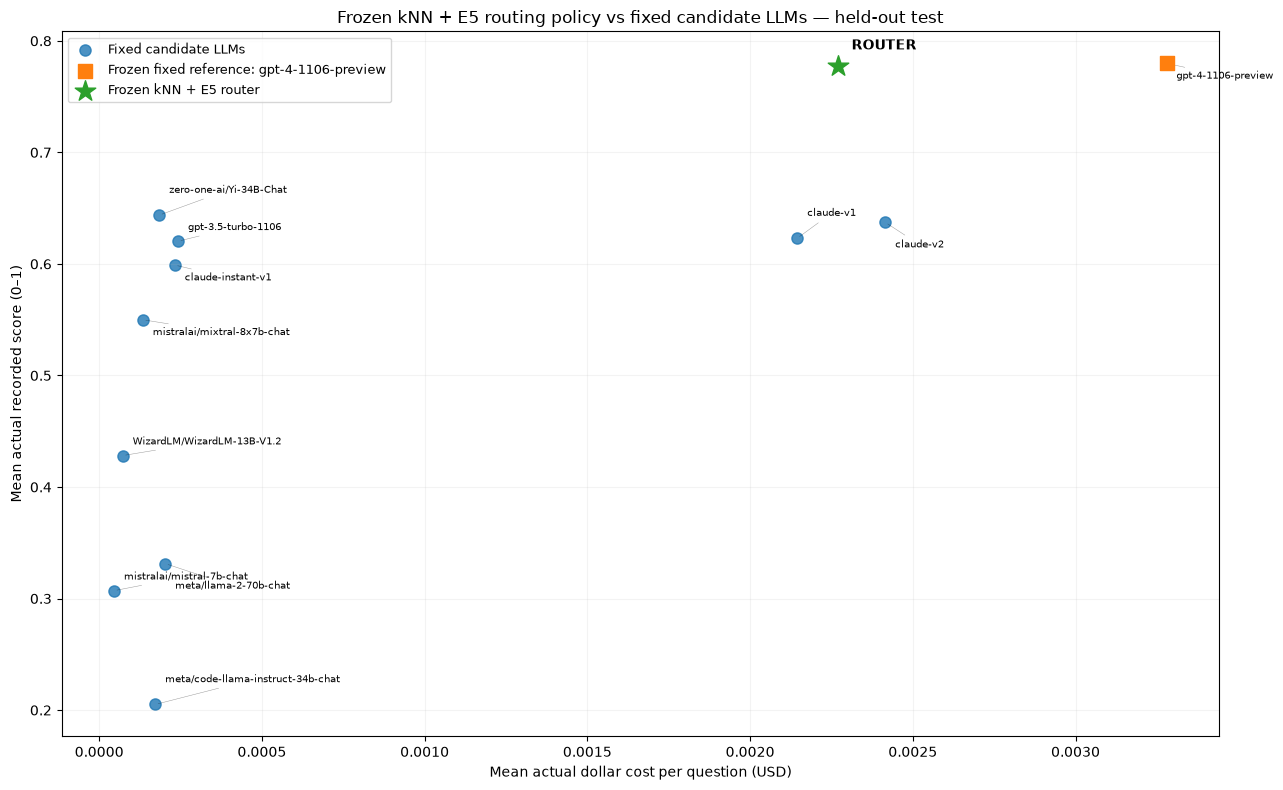

,llm,mean_recorded_score,mean_cost_usd,strategy
8,mistralai/mistral-7b-chat,0.307096,0.000046,Fixed LLM
0,WizardLM/WizardLM-13B-V1.2,0.428226,0.000073,Fixed LLM
9,mistralai/mixtral-8x7b-chat,0.549938,0.000135,Fixed LLM
6,meta/code-llama-instruct-34b-chat,0.205068,0.000173,Fixed LLM
10,zero-one-ai/Yi-34B-Chat,0.643822,0.000185,Fixed LLM
7,meta/llama-2-70b-chat,0.331281,0.000203,Fixed LLM
1,claude-instant-v1,0.598945,0.000233,Fixed LLM
4,gpt-3.5-turbo-1106,0.620404,0.000243,Fixed LLM
2,claude-v1,0.623164,0.002146,Fixed LLM
11,ROUTER,0.777384,0.002269,Frozen router


GPT-4 selected in 5093 of 7300 test questions.


In [6]:
fixed = pd.DataFrame({
    "mean_recorded_score": true_scores.mean(axis=0),
    "mean_cost_usd": true_costs.mean(axis=0),
})
fixed.index.name = "llm"
assert fixed.index.tolist() == model_names

fig, ax = plt.subplots(figsize=(13, 8))
other = fixed.drop(index=ref)
ax.scatter(other["mean_cost_usd"], other["mean_recorded_score"],
           marker="o", s=65, alpha=.8, label="Fixed candidate LLMs")
ax.scatter([ref_mean_cost], [ref_mean_score], marker="s", s=115,
           label=f"Frozen fixed reference: {ref}", zorder=4)
ax.scatter([router_mean_cost], [router_mean_score], marker="*", s=240,
           label="Frozen kNN + E5 router", zorder=5)

# Show the exact LLM name, not an invented nickname; offsets cycle to limit overlaps.
for j, (name, r) in enumerate(fixed.iterrows()):
    dy = (8, -11, 16, -18)[j % 4]
    ax.annotate(name, (r["mean_cost_usd"], r["mean_recorded_score"]),
                xytext=(7, dy), textcoords="offset points", fontsize=7.5,
                arrowprops={"arrowstyle":"-", "lw":0.35, "alpha":0.4})
ax.annotate("ROUTER", (router_mean_cost, router_mean_score),
            xytext=(10, 12), textcoords="offset points", fontsize=10, weight="bold")
ax.set_xlabel("Mean actual dollar cost per question (USD)")
ax.set_ylabel("Mean actual recorded score (0–1)")
ax.set_title("Frozen kNN + E5 routing policy vs fixed candidate LLMs — held-out test")
ax.grid(alpha=.15)
ax.legend(loc="best", fontsize=9)
fig.tight_layout()
plt.show()

fixed_comparison = pd.concat([fixed.reset_index().assign(strategy="Fixed LLM"),
    pd.DataFrame([{"llm":"ROUTER", "mean_recorded_score":router_mean_score,
                   "mean_cost_usd":router_mean_cost,"strategy":"Frozen router"}])],ignore_index=True)
display(fixed_comparison.sort_values("mean_cost_usd"))
print(f"GPT-4 selected in {(selected_models == 'gpt-4-1106-preview').sum()} of {len(selected_models)} test questions.")

## 6. Export reproducible results (no model or policy refitting)

Reports include the frozen configuration, model-run provenance, source validation bundle and plot. Large prediction tables are placed under `4_Final_Test/experiment_outputs/`; add this path to the project's `.gitignore`. Avoid publishing individual test labels or evaluating alternative policies on these labels.

In [7]:
out_base = project_root / "4_Final_Test" / "experiment_outputs"
out_dir = out_base / datetime.now(timezone.utc).strftime("knn_e5_test_%Y%m%dT%H%M%S_%fZ")
out_dir.mkdir(parents=True, exist_ok=False)
scorecard.to_csv(out_dir / "test_kpi_scorecard.csv", index=False)
cost_diagnostics.to_csv(out_dir / "test_cost_diagnostics_per_llm.csv", index=False)
binary_diagnostics.to_csv(out_dir / "test_binary_diagnostics_if_available.csv", index=False)
selected.to_csv(out_dir / "selected_models_test.csv")
fixed_comparison.to_csv(out_dir / "fixed_llm_comparison.csv", index=False)
predicted_scores.to_pickle(out_dir / "test_predicted_expected_scores.pkl")
predicted_costs.to_pickle(out_dir / "test_predicted_costs.pkl")
fig.savefig(out_dir / "test_score_cost_labeled.png", dpi=180, bbox_inches="tight")
config = {
    "method":METHOD, "feature":FEATURE, "score_type":SCORE_TYPE,
    "lambda":float(FROZEN_LAMBDA), "reference_llm":ref,
    "reference_selection_provenance":"frozen_policy_validation",
    "lambda_confirmed_before_test": LAMBDA_CONFIRMED,
    "reference_confirmed_before_test": REFERENCE_CONFIRMED,
    "model_run":str(run_dir), "model_run_created_utc":manifest.get("created_utc"),
    "validation_prediction_prefix":validation_prefix,
    "max_validation_score_difference":score_diff,
    "max_validation_cost_difference":cost_diff,
    "k_score":selected_score_k, "k_cost":selected_cost_k,
    "model_names":model_names,
    "binary_metrics_available":strict_binary,
    "policy_rule":"argmax(expected_5class_score - lambda * predicted_dollar_cost)",
    "note":"Test results did not select reference, lambda, embedding, or neighbor counts.",
}
(out_dir / "frozen_configuration.json").write_text(json.dumps(config, indent=2))
print("Saved final test outputs to:", out_dir)
print("Share test_kpi_scorecard.csv and test_score_cost_labeled.png with your team.")

Saved final test outputs to: /Users/haotanhan/Documents/Career/DataScience/ErdosBootCamp/Project/fall-2026-right-for-less/fall-2026-right-for-less/4_Final_Test/experiment_outputs/knn_e5_test_20261024T001846_117927Z
Share test_kpi_scorecard.csv and test_score_cost_labeled.png with your team.
